# Diagnose eps/eps Heun resolution

## Objective

Determine whether finer Heun grids repair the saved eps/eps sampling trajectory.

Keep the trained checkpoints, saved noise bank, data tensors, time interval, exact division, and output fixed.

Change only the number of Heun steps from 50 to 200 and 500.

Measure epsilon error and induced velocity error on controlled path states.


In [1]:
# Load the fixed paths and analysis libraries.
import json
import os
import subprocess
import sys
from pathlib import Path

# Use a writable cache before Matplotlib imports its configuration.
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mem_param_matplotlib")

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torchvision.utils import make_grid

from mem_param_src.runners.artifacts import load_torch

# Find the repository root because notebook runners can change the working directory.
notebook_cwd = Path.cwd().resolve()
repo_root = next(
    candidate
    for candidate in (notebook_cwd, *notebook_cwd.parents)
    if (candidate / "pyproject.toml").is_file()
)

run_dir = repo_root / "outputs/sanity/flowers102_runner_eps_eps_exact_64_n8_10k_20260820T191129Z"
suite_dir = repo_root / "protoypinging_and_trubbleshoting/eps_eps_sampling"
replay_script = suite_dir / "scripts/replay_heun_resolution.py"
conditioning_script = suite_dir / "scripts/measure_eps_conditioning.py"
resolution_steps = (50, 200, 500)

run_record = json.loads((run_dir / "run.json").read_text())
device = run_record["resolved_device"]  # Match the device used by the saved training run.
if device == "mps":
    assert torch.backends.mps.is_available(), "The saved MPS device is not available."

display({"run_dir": str(run_dir), "device": device, "resolution_steps": resolution_steps})


{'run_dir': '/Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/sanity/flowers102_runner_eps_eps_exact_64_n8_10k_20260820T191129Z',
 'device': 'mps',
 'resolution_steps': (50, 200, 500)}

## Problem and test

The epsilon predictor defines velocity through the following conversion:

$$
\hat v(z_t,t)=\frac{z_t-\hat\epsilon(z_t,t)}{t}.
$$

An epsilon error therefore becomes a velocity error divided by t.

Use 200 and 500 steps to test solver resolution without retraining.

Use controlled path probes to test the learned field near the noise endpoint.


In [2]:
# Verify the saved run and immutable diagnostic controls.
config = json.loads((run_dir / "config.json").read_text())
bundle = load_torch(run_dir / "data_bundle.pt")
z_init = load_torch(run_dir / "z_init.pt")

assert config["framework"]["prediction_space"] == "eps"
assert config["framework"]["loss_space"] == "eps"
assert config["sampling"]["method"] == "heun"
assert config["sampling"]["n_steps"] == 50
assert config["sampling"]["use_safe_division"] is False
assert config["sampling"]["start_time"] == 0.01
assert config["sampling"]["end_time"] == 0.99
assert config["sampling"]["output"] == "x_1"
assert bundle["train"].shape == (8, 3, 64, 64)
assert z_init.shape == (64, 3, 64, 64)

controls = pd.DataFrame(
    [
        ["prediction/loss", "eps/eps"],
        ["solver", "Heun"],
        ["time interval", "0.01 to 0.99"],
        ["division", "exact"],
        ["output", "x_1"],
        ["saved samples", z_init.shape[0]],
        ["checkpoints", len(list((run_dir / "checkpoints").glob("step_*.pt")))],
    ],
    columns=["control", "value"],
)
display(controls)


,control,value
0,prediction/loss,eps/eps
1,solver,Heun
2,time interval,0.01 to 0.99
3,division,exact
4,output,x_1
5,saved samples,64
6,checkpoints,5


## Replay the saved checkpoints

Run two named evaluations with 200 and 500 Heun steps.

The replay script reuses complete matching evaluations.

The replay script rejects partial or mismatched evaluation directories.


In [3]:
# Replay every checkpoint with the two finer Heun grids.
environment = os.environ.copy()
environment["PYTHONPATH"] = str(repo_root)  # Import the clean package without changing installation state.
replay_command = [
    sys.executable,
    str(replay_script),
    "--run-dir",
    str(run_dir),
    "--steps",
    "200",
    "500",
    "--device",
    device,
]
replay_result = subprocess.run(
    replay_command,
    cwd=repo_root,
    env=environment,
    check=True,
    capture_output=True,
    text=True,
)
print(replay_result.stdout.strip())


reuse /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/sanity/flowers102_runner_eps_eps_exact_64_n8_10k_20260820T191129Z/evaluations/heun_200_exact
reuse /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/sanity/flowers102_runner_eps_eps_exact_64_n8_10k_20260820T191129Z/evaluations/heun_500_exact


## Measure endpoint conditioning

Evaluate the final model on exact interpolation states.

Pair the saved training images with the saved noise prefix.

Compare epsilon error with the induced velocity error at fixed times.


In [4]:
# Measure epsilon and velocity errors on fixed controlled states.
conditioning_command = [
    sys.executable,
    str(conditioning_script),
    "--run-dir",
    str(run_dir),
    "--device",
    device,
]
conditioning_result = subprocess.run(
    conditioning_command,
    cwd=repo_root,
    env=environment,
    check=True,
    capture_output=True,
    text=True,
)
print(conditioning_result.stdout.strip())


reuse /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/outputs/sanity/flowers102_runner_eps_eps_exact_64_n8_10k_20260820T191129Z/diagnostics/eps_eps_conditioning_step_010000.json


## Verify the replay controls

Load each final tensor and every checkpoint metric record.

Confirm that the effective settings differ only in the Heun step count.


In [5]:
# Load each evaluation and verify the single changed setting.
evaluation_names = {50: "default", 200: "heun_200_exact", 500: "heun_500_exact"}
samples = {}
metrics = {}
settings = {}
verification_rows = []

for step_count, evaluation_name in evaluation_names.items():
    evaluation_dir = run_dir / "evaluations" / evaluation_name
    settings[step_count] = json.loads((evaluation_dir / "settings.json").read_text())
    metrics[step_count] = json.loads((evaluation_dir / "checkpoint_metrics.json").read_text())
    samples[step_count] = load_torch(evaluation_dir / "final_samples_x_1.pt")

    expected_sampling = dict(config["sampling"])
    expected_sampling["n_steps"] = step_count  # Keep every other saved sampling field fixed.
    assert settings[step_count]["sampling"] == expected_sampling
    assert settings[step_count]["evaluation"] == config["evaluation"]
    assert samples[step_count].shape == z_init.shape
    assert len(metrics[step_count]) == 5

    verification_rows.append(
        {
            "evaluation": evaluation_name,
            "Heun steps": step_count,
            "metric records": len(metrics[step_count]),
            "sample shape": tuple(samples[step_count].shape),
        }
    )

display(pd.DataFrame(verification_rows))


,evaluation,Heun steps,metric records,sample shape
0,default,50,5,"(64, 3, 64, 64)"
1,heun_200_exact,200,5,"(64, 3, 64, 64)"
2,heun_500_exact,500,5,"(64, 3, 64, 64)"


In [6]:
# Summarize raw ranges, valid values, and final checkpoint metrics.
summary_rows = []
for step_count in resolution_steps:
    tensor = samples[step_count]
    final_record = metrics[step_count][-1]
    step_size = (config["sampling"]["end_time"] - config["sampling"]["start_time"]) / step_count
    summary_rows.append(
        {
            "Heun steps": step_count,
            "step size": step_size,
            "initial h/t": step_size / config["sampling"]["start_time"],
            "finite": bool(torch.isfinite(tensor).all()),
            "minimum": float(tensor.min()),
            "maximum": float(tensor.max()),
            "fraction in [-1, 1]": float(((tensor >= -1.0) & (tensor <= 1.0)).float().mean()),
            "mean d1": final_record["mean_d1"],
            "mean r": final_record["mean_r"],
            "f_mem rho 0.3": final_record["f_mem_rho0.3"],
            "f_mem rho 0.5": final_record["f_mem_rho0.5"],
            "f_mem rho 0.7": final_record["f_mem_rho0.7"],
        }
    )

summary = pd.DataFrame(summary_rows).set_index("Heun steps")
display(summary)


,step size,initial h/t,finite,minimum,maximum,"fraction in [-1, 1]",mean d1,mean r,f_mem rho 0.3,f_mem rho 0.5,f_mem rho 0.7
Heun steps,,,,,,,,,,,
50,0.01960,1.960,True,-14.723486,16.012545,0.315552,270.292999,0.988833,0.0,0.0,0.0
200,0.00490,0.490,True,-14.626595,15.846802,0.317542,268.527435,0.988717,0.0,0.0,0.0
500,0.00196,0.196,True,-14.618164,15.832595,0.317691,268.378601,0.988707,0.0,0.0,0.0


In [7]:
# Compare matched final samples across solver resolutions.
difference_rows = []
for first, second in ((50, 200), (200, 500), (50, 500)):
    difference = samples[first] - samples[second]
    difference_rows.append(
        {
            "comparison": f"{first} versus {second}",
            "sample RMSE": float(difference.square().mean().sqrt()),
            "mean absolute difference": float(difference.abs().mean()),
            "maximum absolute difference": float(difference.abs().max()),
        }
    )

differences = pd.DataFrame(difference_rows).set_index("comparison")
convergence_ratio = (
    differences.loc["200 versus 500", "sample RMSE"]
    / differences.loc["50 versus 200", "sample RMSE"]
)
display(differences)
print(f"Convergence ratio, RMSE(200,500) / RMSE(50,200): {convergence_ratio:.6f}")


,sample RMSE,mean absolute difference,maximum absolute difference
comparison,,,
50 versus 200,0.029318,0.022658,0.384638
200 versus 500,0.002376,0.001829,0.030254
50 versus 500,0.031681,0.024478,0.414893


Convergence ratio, RMSE(200,500) / RMSE(50,200): 0.081034


## Inspect the generated images

Use one matched 64-sample grid for every resolution.

Clamp values only for display. Use the raw summary for range assessment.


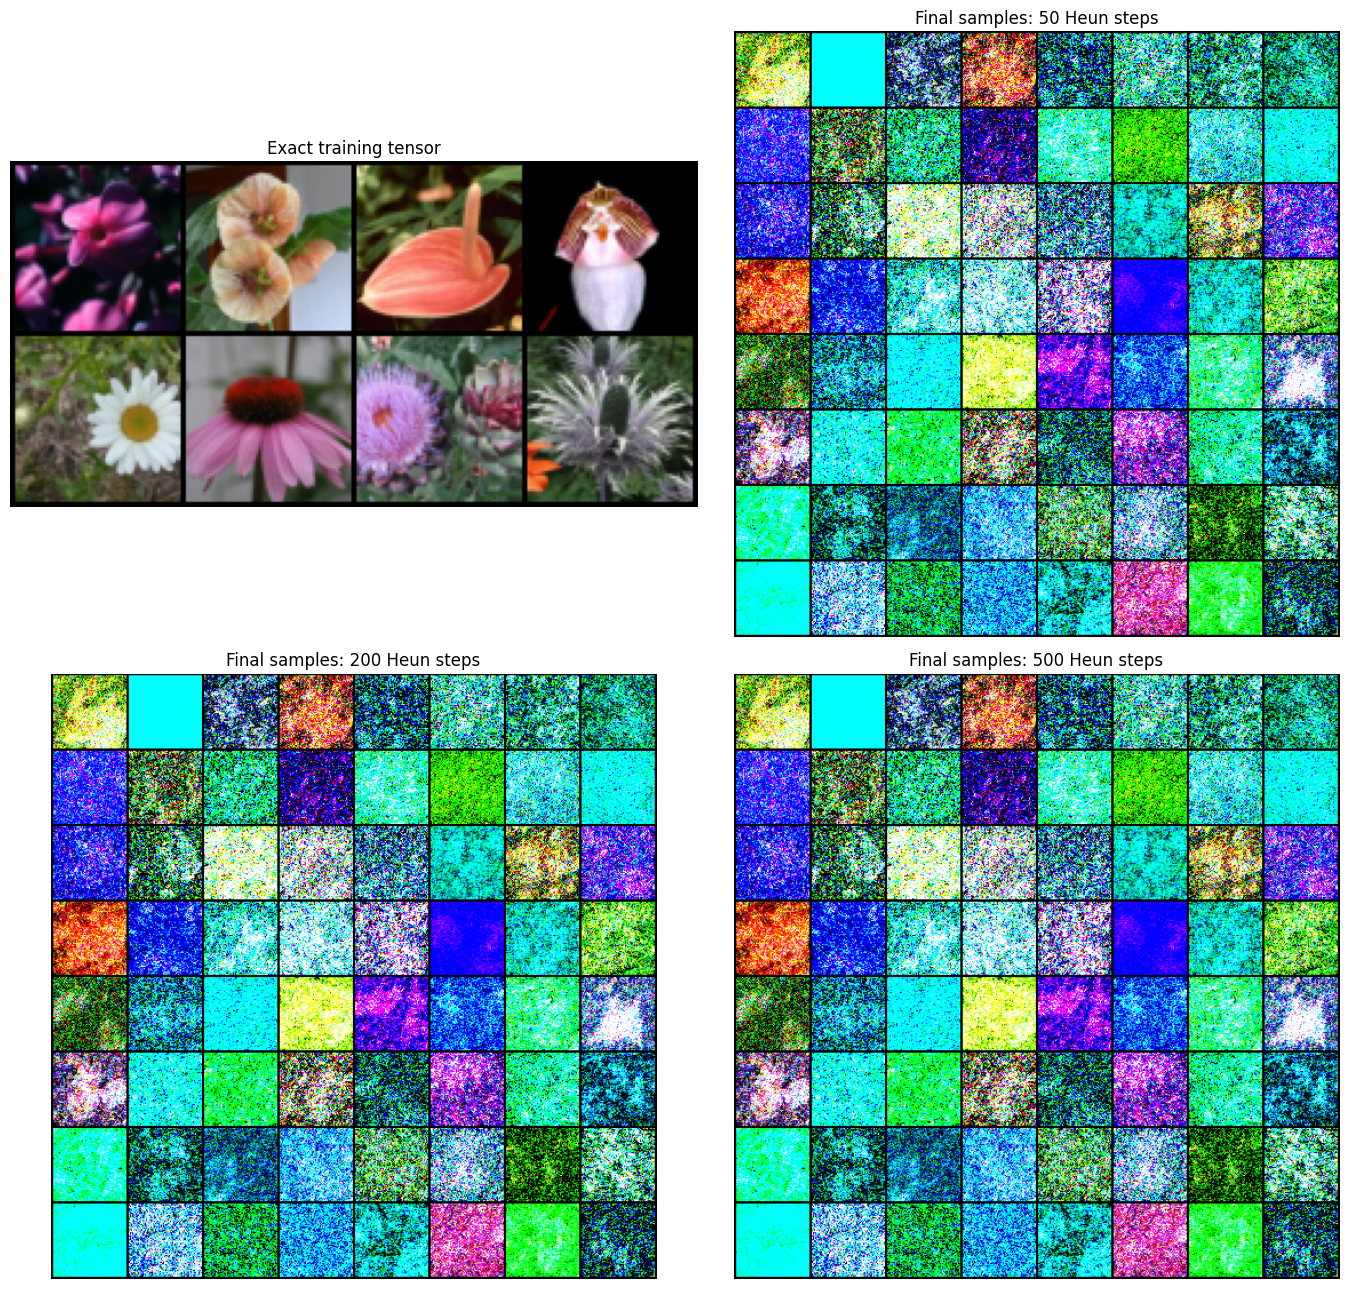

In [8]:
# Display the fixed training images and matched generated samples.
panels = [("Exact training tensor", bundle["train"])]
panels.extend((f"Final samples: {step_count} Heun steps", samples[step_count]) for step_count in resolution_steps)

figure, axes = plt.subplots(2, 2, figsize=(14, 13))
for axis, (title, tensor) in zip(axes.flat, panels):
    display_tensor = (tensor.detach().cpu().clamp(-1.0, 1.0) + 1.0) / 2.0
    columns = 4 if title == "Exact training tensor" else 8
    grid = make_grid(display_tensor, nrow=columns, padding=2)
    axis.imshow(grid.permute(1, 2, 0))
    axis.set_title(title)
    axis.axis("off")

plt.tight_layout()
plt.show()


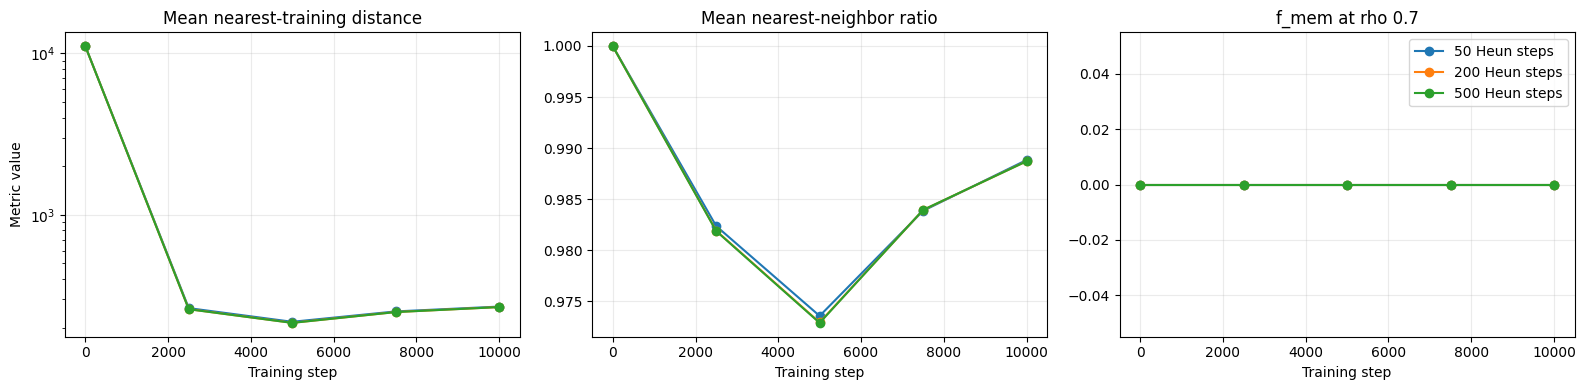

In [9]:
# Plot checkpoint metrics for every solver resolution.
metric_specs = (
    ("mean_d1", "Mean nearest-training distance", True),
    ("mean_r", "Mean nearest-neighbor ratio", False),
    ("f_mem_rho0.7", "f_mem at rho 0.7", False),
)
figure, axes = plt.subplots(1, 3, figsize=(16, 4))

for axis, (metric_key, title, use_log_scale) in zip(axes, metric_specs):
    for step_count in resolution_steps:
        checkpoint_steps = [record["step"] for record in metrics[step_count]]
        values = [record[metric_key] for record in metrics[step_count]]
        axis.plot(checkpoint_steps, values, marker="o", label=f"{step_count} Heun steps")
    if use_log_scale:
        axis.set_yscale("log")  # Keep the large untrained distance visible.
    axis.set_title(title)
    axis.set_xlabel("Training step")
    axis.grid(alpha=0.25)

axes[0].set_ylabel("Metric value")
axes[-1].legend()
plt.tight_layout()
plt.show()


## Inspect epsilon conditioning

The controlled probe uses exact path states with known epsilon and velocity targets.

It does not measure error on generated trajectory states.


In [10]:
# Load the controlled endpoint-conditioning report.
conditioning_path = run_dir / "diagnostics/eps_eps_conditioning_step_010000.json"
conditioning_report = json.loads(conditioning_path.read_text())
conditioning = pd.DataFrame(conditioning_report["records"])
conditioning["relative MSE difference"] = (
    (conditioning["velocity_mse"] - conditioning["induced_velocity_mse"]).abs()
    / conditioning["induced_velocity_mse"].clip(lower=1e-30)
)

display(
    conditioning[
        [
            "t",
            "amplification",
            "eps_rmse",
            "velocity_rmse",
            "conversion_max_abs_difference",
            "relative MSE difference",
        ]
    ]
)


,t,amplification,eps_rmse,velocity_rmse,conversion_max_abs_difference,relative MSE difference
0,0.0100,100.000000,0.027713,2.771305,2.241135e-05,6.208710e-08
1,0.0125,80.000000,0.027890,2.231188,1.478195e-05,9.578509e-08
2,0.0200,50.000000,0.028660,1.432978,1.192093e-05,1.161076e-07
3,0.0500,20.000000,0.034310,0.686206,3.337860e-06,1.265817e-07
4,0.1000,10.000000,0.046833,0.468333,1.907349e-06,6.793767e-08
5,0.2500,4.000000,0.070349,0.281395,4.768372e-07,0.000000e+00
6,0.5000,2.000000,0.075453,0.150905,2.384186e-07,0.000000e+00
7,0.7500,1.333333,0.093653,0.124871,4.768372e-07,5.972828e-08
8,0.9900,1.010101,0.583071,0.588961,2.384186e-07,8.591662e-08


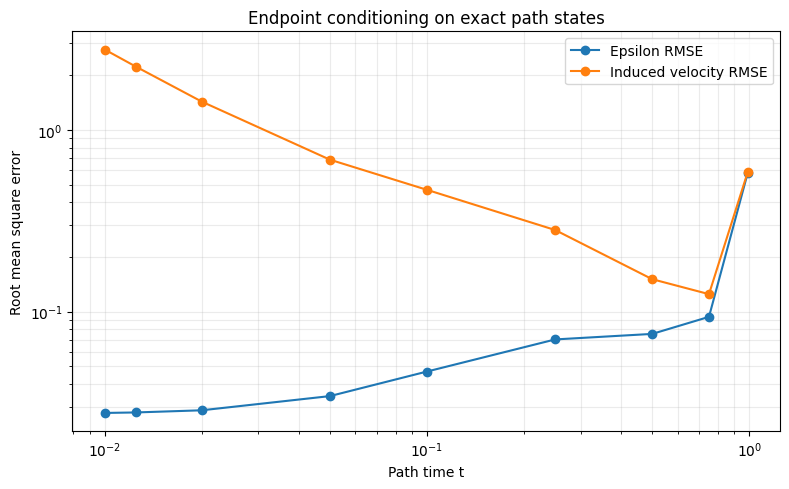

In [11]:
# Plot prediction error against the controlled path time.
figure, axis = plt.subplots(figsize=(8, 5))
axis.loglog(conditioning["t"], conditioning["eps_rmse"], marker="o", label="Epsilon RMSE")
axis.loglog(conditioning["t"], conditioning["velocity_rmse"], marker="o", label="Induced velocity RMSE")
axis.set_xlabel("Path time t")
axis.set_ylabel("Root mean square error")
axis.set_title("Endpoint conditioning on exact path states")
axis.grid(which="both", alpha=0.25)
axis.legend()
plt.tight_layout()
plt.show()


In [12]:
# Collect the evidence needed for the next decision.
evidence = pd.Series(
    {
        "RMSE 50 versus 200": differences.loc["50 versus 200", "sample RMSE"],
        "RMSE 200 versus 500": differences.loc["200 versus 500", "sample RMSE"],
        "convergence ratio": convergence_ratio,
        "50-step mean d1": summary.loc[50, "mean d1"],
        "200-step mean d1": summary.loc[200, "mean d1"],
        "500-step mean d1": summary.loc[500, "mean d1"],
        "epsilon RMSE at t=0.01": conditioning.loc[conditioning["t"] == 0.01, "eps_rmse"].iloc[0],
        "velocity RMSE at t=0.01": conditioning.loc[conditioning["t"] == 0.01, "velocity_rmse"].iloc[0],
    },
    name="value",
)
display(evidence.to_frame())


,value
RMSE 50 versus 200,0.029318
RMSE 200 versus 500,0.002376
convergence ratio,0.081034
50-step mean d1,270.292999
200-step mean d1,268.527435
500-step mean d1,268.378601
epsilon RMSE at t=0.01,0.027713
velocity RMSE at t=0.01,2.771305


## Decision rules

- Treat similar 200- and 500-step results as solver convergence.
- Blame coarse resolution when finer converged samples improve substantially.
- Investigate the learned field when finer converged samples remain invalid.
- Investigate stiffness when results change irregularly across step counts.

If the field remains poor, compare eps/eps with v/v plus eps-equivalent weighting.

Do not change safe division until this solver-resolution comparison is complete.

## Current result

The 200- and 500-step samples are visually and numerically converged. Both grids remain colored noise.

Their sample RMSE is 0.002376. Their mean nearest-training distances are 268.53 and 268.38.

At t = 0.01, epsilon RMSE is 0.0277 and induced velocity RMSE is 2.7713.

The conversion implementation agrees with the direct formula within 2.25e-5.

Coarse Heun resolution is not the main failure cause for this saved model.

The next controlled experiment should compare eps/eps with v/v plus eps-equivalent weighting.
